# 01 - Data Exploration
Explores the two processed datasets (TCGA COADREAD, GDSC2 colorectal cell lines) and the unified ferroptosis gene signature. Run `python main.py` first to generate the underlying files.

In [1]:
import sys, json
sys.path.insert(0, '../src')
import pandas as pd
import matplotlib.pyplot as plt

gene_sig = pd.read_csv('../data/unified_gene_signature.csv')
tcga = pd.read_csv('../data/processed/tcga_coadread_processed.csv')
gdsc = pd.read_csv('../data/processed/gdsc_colorectal_dose_response_processed.csv')
print('Unified ferroptosis gene signature:', gene_sig.shape)
print('TCGA COADREAD processed:', tcga.shape)
print('GDSC colorectal dose-response processed:', gdsc.shape)

Unified ferroptosis gene signature: (35, 5)
TCGA COADREAD processed: (592, 102)
GDSC colorectal dose-response processed: (11511, 41)


## Ferroptosis gene signature composition

In [2]:
gene_sig['category'].value_counts()

category
crc_prognostic_signature    27
core_mechanism               8
Name: count, dtype: int64

## TCGA: MSI label distribution and survival fields

msi_label
MSS/MSI-L    503
MSI-H         89
Name: count, dtype: int64


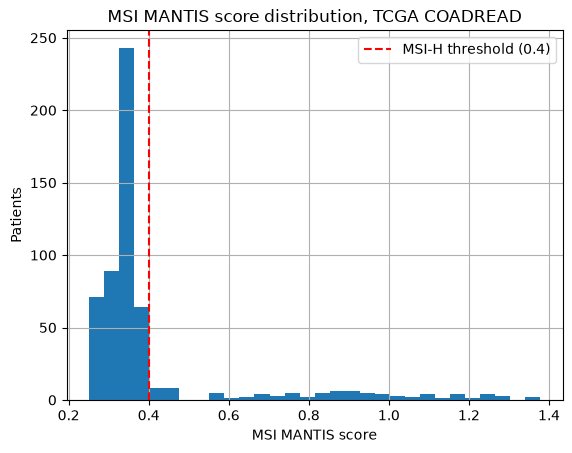

In [3]:
print(tcga['msi_label'].value_counts(dropna=False))
tcga['MSI_SCORE_MANTIS'].astype(float).hist(bins=30)
plt.axvline(0.4, color='red', linestyle='--', label='MSI-H threshold (0.4)')
plt.xlabel('MSI MANTIS score'); plt.ylabel('Patients'); plt.legend()
plt.title('MSI MANTIS score distribution, TCGA COADREAD')
plt.show()

## GDSC: colorectal cell lines, drugs, and response distribution

Cell lines: 44 | Drugs: 268


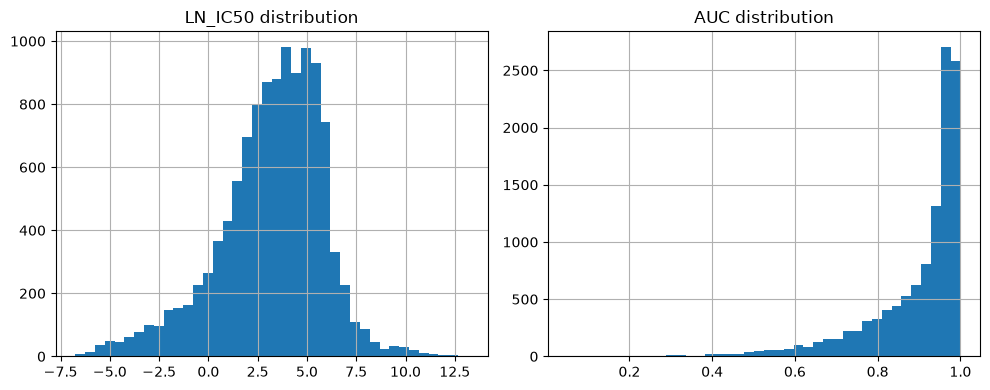

In [4]:
print('Cell lines:', gdsc['COSMIC_ID'].nunique(), '| Drugs:', gdsc['DRUG_NAME'].nunique())
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
gdsc['LN_IC50'].hist(bins=40, ax=axes[0]); axes[0].set_title('LN_IC50 distribution')
gdsc['AUC'].hist(bins=40, ax=axes[1]); axes[1].set_title('AUC distribution')
plt.tight_layout(); plt.show()

## Missingness check on ferroptosis gene panel (TCGA)

In [5]:
with open('../data/processed/tcga_preprocessing_metadata.json') as f:
    meta = json.load(f)
genes = meta['ferroptosis_genes_used']
tcga[genes].isna().mean().sort_values(ascending=False).head(10)

ABCC1       0.0
ACSL4       0.0
AIFM2       0.0
AKR1C1      0.0
ALOX12      0.0
ATF3        0.0
ATG5        0.0
ATG7        0.0
ATP6V1G2    0.0
BID         0.0
dtype: float64